<a href="https://colab.research.google.com/github/Divyesh-SP/DSA0405-FUNDAMENTALS-OF-DATA-SCIENCE/blob/main/DSA04_CO5_Machine_Learning_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA04 CO5 — Retail Lending Machine Learning
Run all cells in Google Colab. Synthetic teaching data only, not a deployable lending system.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
from pathlib import Path
from scipy import stats
from scipy.special import expit
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import *
from sklearn.calibration import calibration_curve
from IPython.display import display
SEED=42; rng=np.random.default_rng(SEED)
OUT=Path('CO5_outputs'); OUT.mkdir(exist_ok=True)
CV=StratifiedKFold(3,shuffle=True,random_state=SEED)
def show(name):
    plt.tight_layout(); plt.savefig(OUT/(name+'.png'),dpi=130); plt.show(); plt.close()
def table(df,name):
    display(df.round(4)); df.to_csv(OUT/(name+'.csv'),index=True)

## Pre-experiment predictions (Task 9)
Record these before executing the models: scaling improves distance-based methods but barely changes CART; weighted logistic regression is expected to have highest recall; deeper trees improve training scores but validation eventually stalls; around three segments may be useful. These are hypotheses, not measured findings.

In [ ]:
N=12000
segment=rng.integers(0,3,N); income=rng.lognormal(12.6+.45*segment,.55,N)
age=rng.integers(21,66,N); tenure=rng.integers(12,85,N)
late=rng.poisson(.6,N); util=rng.beta(2,3,N); loan=income*rng.uniform(.15,1.2,N)
D=pd.DataFrame(dict(age=age,gender=rng.choice(['F','M'],N),region=rng.choice(['North','South','East','West'],N),employment=rng.choice(['Salaried','Self-employed','Other'],N),years_employed=np.minimum(age-18,rng.integers(0,30,N)),income=income,household=rng.integers(1,7,N),balance=income*rng.uniform(.02,.22,N),products=segment+1,loan=loan,tenure=tenure,interest=rng.uniform(7,19,N),loan_income=loan/income,late=late,utilisation=util,months_since_delinquency=rng.integers(0,49,N)))
D['years_employed']=D.years_employed.astype(float)
D['spend']=np.maximum(100,900+.012*income+.025*D.balance+500*D.products+rng.normal(0,1700,N))
risk=1.05*late+3.5*util+1.1*D.loan_income-.000001*income
# Choose intercept to target 8% expected defaults
from scipy.optimize import brentq
intercept=brentq(lambda a: expit(a+risk).mean()-.08,-30,10)
D['default']=rng.binomial(1,expit(intercept+risk))
D.loc[rng.choice(N,840,False),'income']=np.nan
D.loc[rng.choice(N,600,False),'years_employed']=np.nan
D.loc[rng.choice(N,200,False),'employment']=' salaried '
D.loc[rng.choice(N,40,False),'balance']*=25
D.to_csv(OUT/'customers_raw.csv',index=False)
print(D.shape,'Default rate:',D.default.mean()); display(D.head())

(12000, 18) Default rate: 0.08258333333333333


,age,gender,region,employment,years_employed,income,household,balance,products,loan,tenure,interest,loan_income,late,utilisation,months_since_delinquency,spend,default
0,29,F,South,Salaried,11.0,167653.286063,4,23505.895146,1,1.976298e+05,80,17.503640,1.178801,1,0.455871,47,3587.583980,0
1,35,F,West,Salaried,17.0,951171.369636,1,50850.333002,3,1.106633e+06,84,7.734355,1.163442,1,0.176926,25,15688.247135,0
2,28,M,East,Self-employed,10.0,332987.099334,2,9734.500400,2,3.503636e+05,19,16.580985,1.052184,1,0.802980,2,6918.398218,1
3,47,F,East,Salaried,29.0,187777.591538,6,23240.190694,2,9.837956e+04,41,8.436568,0.523915,0,0.166306,7,9099.050518,0
4,27,F,East,Salaried,4.0,NaN,4,9678.857970,2,4.293485e+05,51,15.477282,1.081267,2,0.490125,15,8575.020595,1


## Task 1 – Formulate problems
One row is one customer. Predict default in the next 12 months from historical observations; predict future monthly card spend from past attributes (synthetic proxy); segment using available account characteristics. Never use either outcome as a predictor. Missed default costs 5 units; refused good customer costs 1 (illustrative).

In [ ]:
table(pd.DataFrame([['Credit risk','Classification','default','Recall, F1, PR-AUC','Avoid costly defaults'],['Portfolio','Regression','spend','MAE, RMSE, R2','Funding forecast'],['Marketing','Clustering','None','Silhouette, stability','Relevant offers']],columns=['Team','Problem','Target','Metric','Business goal']),'problem_mapping')

,Team,Problem,Target,Metric,Business goal
0,Credit risk,Classification,default,"Recall, F1, PR-AUC",Avoid costly defaults
1,Portfolio,Regression,spend,"MAE, RMSE, R2",Funding forecast
2,Marketing,Clustering,None,"Silhouette, stability",Relevant offers


## Task 2 – Preparation and baselines
Median imputation is robust; one-hot encoding avoids arbitrary category order. Scale distance-based models. Keep extreme balances for sensitivity analysis rather than silently deleting. Exclude gender from prediction and retain it for audit only. Fit preprocessing inside each training fold.

,missing
age,0
gender,0
region,0
employment,0
years_employed,600
income,840
household,0
balance,0
products,0
loan,0


,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
Baseline,0.9175,0.0,0.0,0.0,0.5,0.0825,990


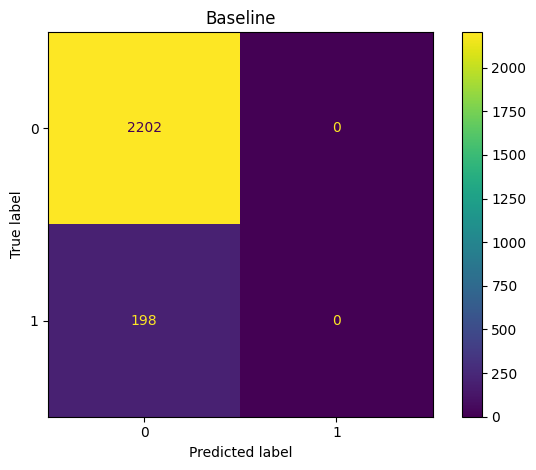

Mean spend baseline: {'MAE': 4968.740878426424, 'RMSE': np.float64(7097.50107332335), 'R2': -0.000305787010387526}
Prepared shape (9600, 20) missing after preparation 0


In [ ]:
table(D.isna().sum().to_frame('missing'),'missing_audit')
D['employment']=D.employment.str.strip().str.lower()
X=D.drop(columns=['default','spend','gender']); y=D.default
A,B=train_test_split(np.arange(N),test_size=.2,stratify=y,random_state=SEED)
T,V=train_test_split(A,test_size=.25,stratify=y.iloc[A],random_state=SEED)
num=X.select_dtypes('number').columns.tolist(); cat=X.select_dtypes('object').columns.tolist()
def prep(scale=True, columns=None):
    cols=X.columns if columns is None else columns
    ns=[v for v in cols if v not in cat]; cs=[v for v in cols if v in cat]
    return ColumnTransformer([('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler() if scale else 'passthrough'),ns),('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore')),cs)],sparse_threshold=0)
def model(est,scale=True): return make_pipeline(prep(scale),est)
def metrics(y,pred,prob):
    tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
    return dict(accuracy=accuracy_score(y,pred),precision=precision_score(y,pred,zero_division=0),recall=recall_score(y,pred,zero_division=0),F1=f1_score(y,pred,zero_division=0),ROC_AUC=roc_auc_score(y,prob),PR_AUC=average_precision_score(y,prob),cost=5*fn+fp)
models={}; results={}; times={}
def evaluate(name,est,threshold=.5):
    start=time.perf_counter(); prob=est.predict_proba(X.iloc[B])[:,1]; times[name]=(time.perf_counter()-start)*1000/len(B)
    pred=(prob>=threshold).astype(int); results[name]=metrics(y.iloc[B],pred,prob); models[name]=(est,threshold)
    display(pd.DataFrame([results[name]],index=[name])); ConfusionMatrixDisplay.from_predictions(y.iloc[B],pred); plt.title(name); show(name.replace(' ','_'))
base=model(DummyClassifier(strategy='most_frequent')); base.fit(X.iloc[A],y.iloc[A]); evaluate('Baseline',base)
def regmetrics(actual,pred): return dict(MAE=mean_absolute_error(actual,pred),RMSE=np.sqrt(mean_squared_error(actual,pred)),R2=r2_score(actual,pred))
print('Mean spend baseline:',regmetrics(D.spend.iloc[B],np.repeat(D.spend.iloc[A].mean(),len(B))))
z=prep().fit_transform(X.iloc[A]); print('Prepared shape',z.shape,'missing after preparation',np.isnan(z).sum())

## Task 3 – kNN
Euclidean distance, scaled features, cross-validation using F1. Small k is noisy; large k can hide minority cases.

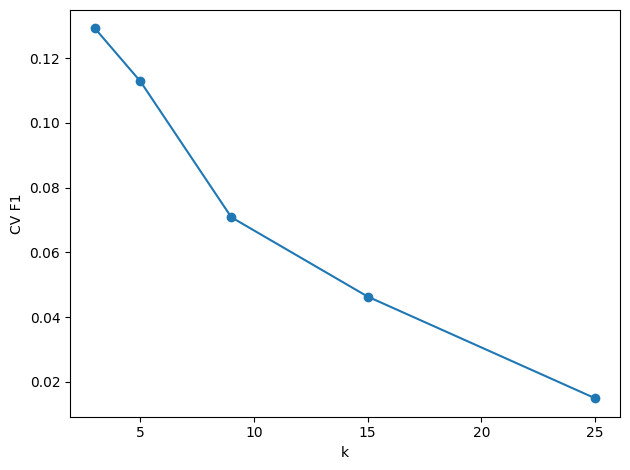

,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
kNN False,0.9025,0.108696,0.025253,0.040984,0.527314,0.087728,1006


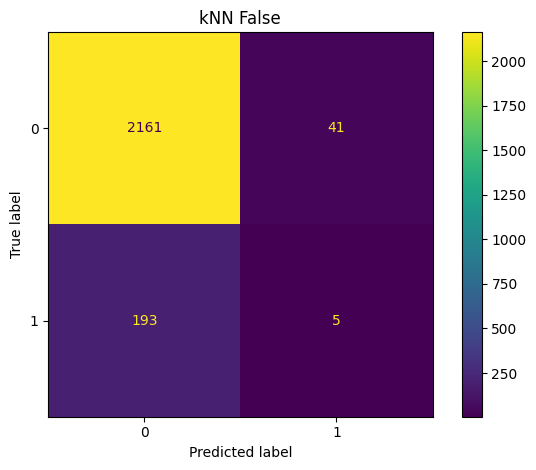

First customer neighbour indices: [[1400 7404 7025]]


,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
kNN True,0.90125,0.217391,0.075758,0.11236,0.602864,0.120012,969


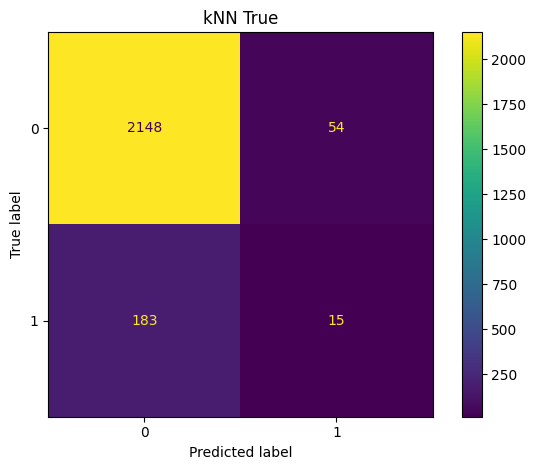

First customer neighbour indices: [[5933 7452 1739]]


In [ ]:
ks=[3,5,9,15,25]; scores=[]
for k in ks:
    scores.append(cross_val_score(model(KNeighborsClassifier(k)),X.iloc[A],y.iloc[A],cv=CV,scoring='f1').mean())
plt.plot(ks,scores,'o-'); plt.xlabel('k'); plt.ylabel('CV F1'); show('knn_k')
k=ks[int(np.argmax(scores))]
for scaled in [False,True]:
    kn=model(KNeighborsClassifier(k),scaled).fit(X.iloc[A],y.iloc[A]); evaluate('kNN '+str(scaled),kn)
    print('First customer neighbour indices:',kn[-1].kneighbors(kn[0].transform(X.iloc[B[:1]]),return_distance=False))

## Task 4 – CART
Example: parent 6 good and 4 default: Gini=1−0.6²−0.4²=0.48. Split into (5 good, 0 default) and (1 good, 4 default): weighted Gini=0.16; gain=0.32. Tune depth and leaf size to reduce overfitting.

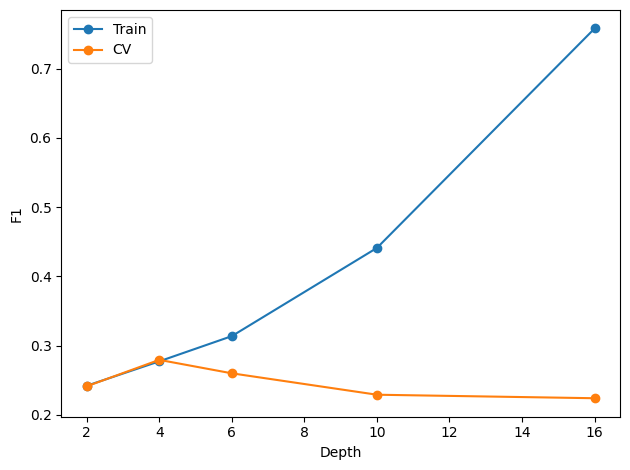

{'decisiontreeclassifier__max_depth': 3, 'decisiontreeclassifier__min_samples_leaf': 20}


,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
CART,0.68625,0.161998,0.671717,0.26104,0.736735,0.22037,1013


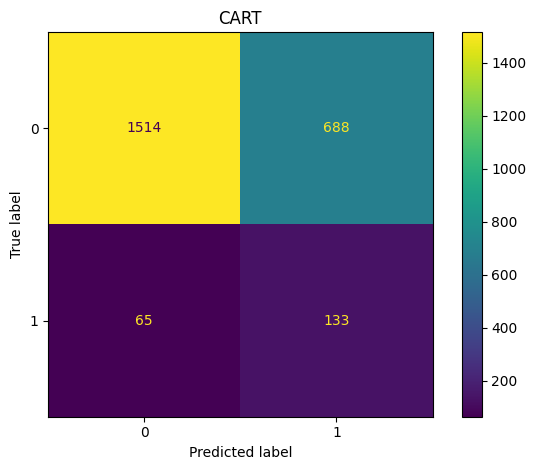

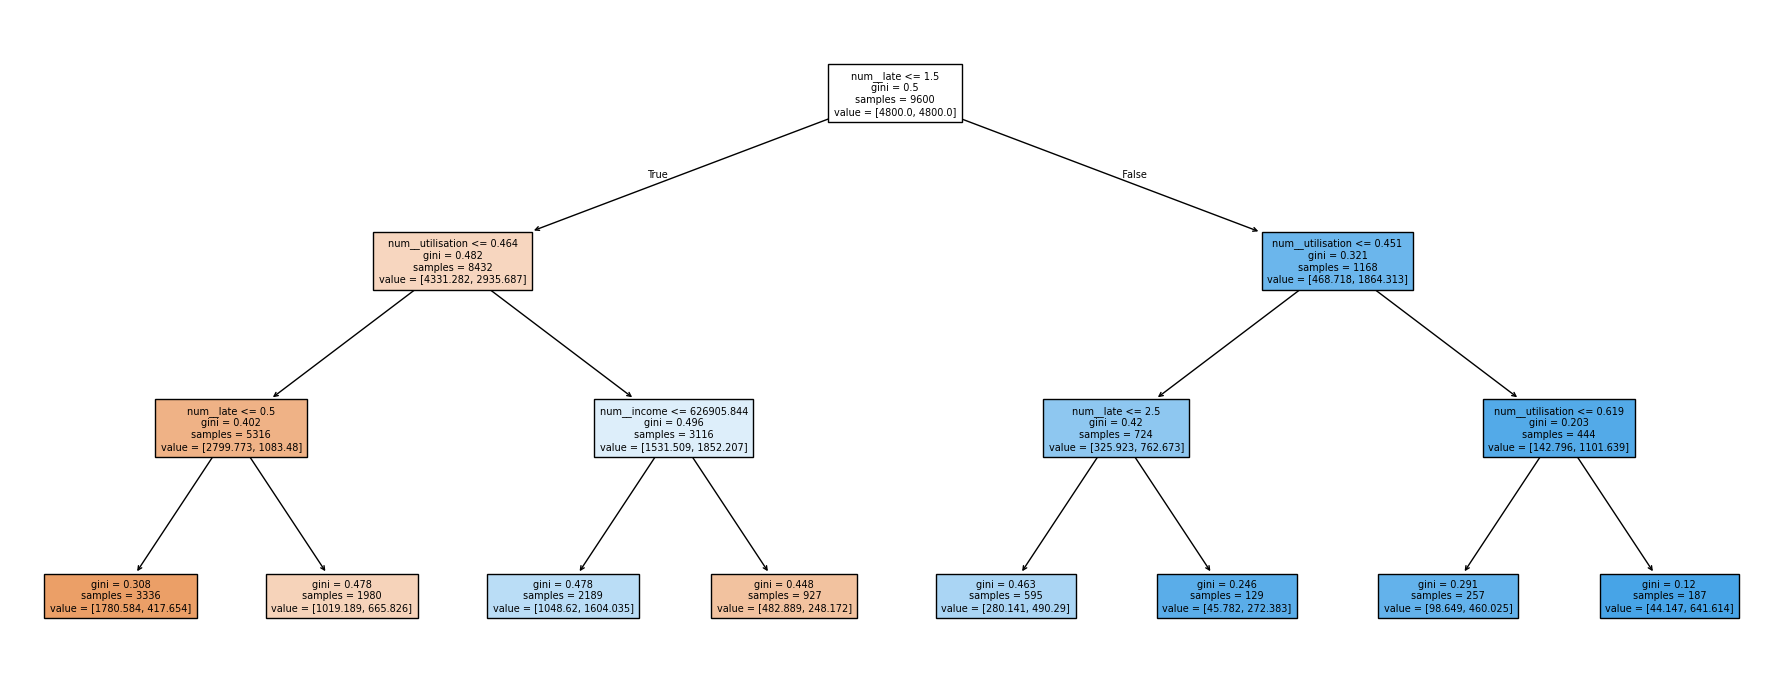

|--- num__late <= 1.50
|   |--- num__utilisation <= 0.46
|   |   |--- num__late <= 0.50
|   |   |   |--- class: 0
|   |   |--- num__late >  0.50
|   |   |   |--- class: 0
|   |--- num__utilisation >  0.46
|   |   |--- num__income <= 626905.84
|   |   |   |--- class: 1
|   |   |--- num__income >  626905.84
|   |   |   |--- class: 0
|--- num__late >  1.50
|   |--- num__utilisation <= 0.45
|   |   |--- num__late <= 2.50
|   |   |   |--- class: 1
|   |   |--- num__late >  2.50
|   |   |   |--- class: 1
|   |--- num__utilisation >  0.45
|   |   |--- num__utilisation <= 0.62
|   |   |   |--- class: 1
|   |   |--- num__utilisation >  0.62
|   |   |   |--- class: 1

Stability across folds: [0.26429102 0.30861723 0.27670251]


In [ ]:
depths=[2,4,6,10,16]; tr=[]; va=[]
for d in depths:
    e=model(DecisionTreeClassifier(max_depth=d,random_state=SEED,class_weight='balanced'),False).fit(X.iloc[A],y.iloc[A]); tr.append(f1_score(y.iloc[A],e.predict(X.iloc[A]))); va.append(cross_val_score(e,X.iloc[A],y.iloc[A],cv=CV,scoring='f1').mean())
plt.plot(depths,tr,'o-',label='Train'); plt.plot(depths,va,'o-',label='CV'); plt.legend(); plt.xlabel('Depth'); plt.ylabel('F1'); show('tree_depth')
g=GridSearchCV(model(DecisionTreeClassifier(random_state=SEED,class_weight='balanced'),False),{'decisiontreeclassifier__max_depth':[3,5,8],'decisiontreeclassifier__min_samples_leaf':[20,80]},scoring='f1',cv=CV).fit(X.iloc[A],y.iloc[A]); tree=g.best_estimator_; print(g.best_params_); evaluate('CART',tree)
names=tree[0].get_feature_names_out(); plt.figure(figsize=(18,7)); plot_tree(tree[-1],feature_names=names,max_depth=3,filled=True,fontsize=7); show('cart_tree'); print(export_text(tree[-1],feature_names=list(names),max_depth=3))
print('Stability across folds:',cross_val_score(tree,X.iloc[A],y.iloc[A],cv=CV,scoring='f1'))

## Task 5 – Linear regression
Least squares minimises squared residuals. Unscaled numeric coefficients are changes in spending per unit, holding other predictors fixed. Correlation does not prove causation.

{'MAE': 1802.1967666600342, 'RMSE': np.float64(2543.382119674853), 'R2': 0.8715467564043373}


,0
num__age,-2.354094
num__years_employed,1.319194
num__income,0.009797
num__household,20.455186
num__balance,0.005068
num__products,773.239430
num__loan,0.006078
num__tenure,0.502742
num__interest,-11.054742
num__loan_income,-3581.407399


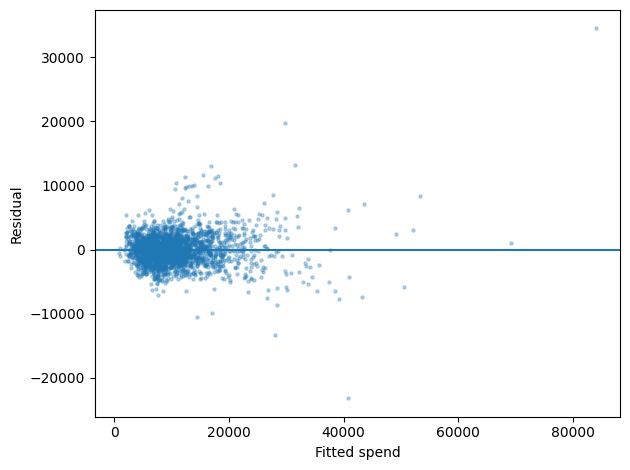

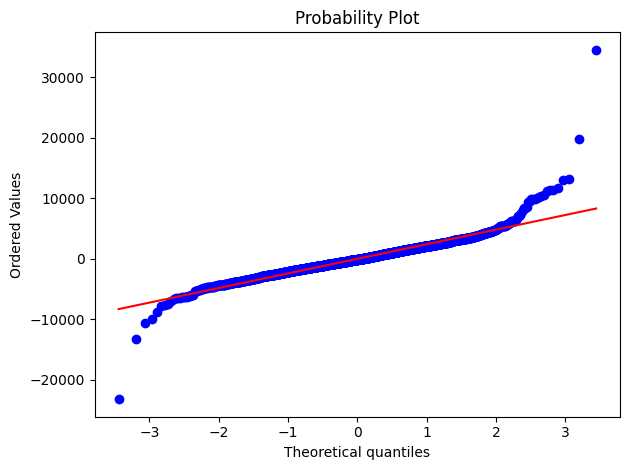

,age,years_employed,income,household,balance,products,loan,tenure,interest,loan_income,late,utilisation,months_since_delinquency
age,1.00,0.39,-0.02,0.00,0.00,0.00,-0.01,0.00,-0.01,0.00,0.01,-0.00,-0.00
years_employed,0.39,1.00,-0.02,0.00,-0.01,-0.01,-0.02,-0.01,-0.02,-0.00,-0.00,0.01,-0.00
income,-0.02,-0.02,1.00,0.00,0.43,0.49,0.80,-0.01,-0.01,0.02,-0.01,-0.01,0.02
household,0.00,0.00,0.00,1.00,-0.00,0.01,0.01,-0.01,0.01,0.01,0.02,0.00,0.01
balance,0.00,-0.01,0.43,-0.00,1.00,0.21,0.32,-0.01,-0.00,0.01,0.01,-0.01,0.01
products,0.00,-0.01,0.49,0.01,0.21,1.00,0.39,-0.01,-0.01,0.00,-0.01,-0.00,0.01
loan,-0.01,-0.02,0.80,0.01,0.32,0.39,1.00,-0.00,0.00,0.49,-0.01,-0.01,0.01
tenure,0.00,-0.01,-0.01,-0.01,-0.01,-0.01,-0.00,1.00,0.01,0.01,0.01,0.02,-0.01
interest,-0.01,-0.02,-0.01,0.01,-0.00,-0.01,0.00,0.01,1.00,0.02,-0.01,0.00,-0.01
loan_income,0.00,-0.00,0.02,0.01,0.01,0.00,0.49,0.01,0.02,1.00,-0.01,-0.01,-0.01


Without loan: {'MAE': 1790.5221784004793, 'RMSE': np.float64(2665.6872031970565), 'R2': 0.8588957087043034}


,0
num__age,-1.516780
num__years_employed,1.183844
num__income,0.013813
num__household,20.228400
num__balance,0.005556
num__products,865.845989
num__tenure,0.236054
num__interest,-9.451232
num__loan_income,-122.286674
num__late,-61.451695


Log target (naive inverse): {'MAE': 3968.484440898159, 'RMSE': np.float64(51716.89517927149), 'R2': -52.11127604585136}


In [ ]:
reg=model(LinearRegression(),False).fit(X.iloc[A],D.spend.iloc[A]); pred=reg.predict(X.iloc[B]); actual=D.spend.iloc[B]; print(regmetrics(actual,pred))
coef=pd.Series(reg[-1].coef_,index=reg[0].get_feature_names_out()); display(coef)
res=actual-pred; plt.scatter(pred,res,s=5,alpha=.3); plt.axhline(0); plt.xlabel('Fitted spend'); plt.ylabel('Residual'); show('residuals')
stats.probplot(res,plot=plt); show('residual_qq')
display(X[num].corr().round(2))
cols=X.columns.drop('loan').tolist(); reduced=make_pipeline(prep(False,cols),LinearRegression()).fit(X.iloc[A],D.spend.iloc[A]); print('Without loan:',regmetrics(actual,reduced.predict(X.iloc[B]))); display(pd.Series(reduced[-1].coef_,index=reduced[0].get_feature_names_out()))
logreg= model(LinearRegression(),False).fit(X.iloc[A],np.log1p(D.spend.iloc[A])); print('Log target (naive inverse):',regmetrics(actual,np.expm1(logreg.predict(X.iloc[B]))))

## Task 6 – Logistic regression
Probability = sigmoid(intercept + weighted features). Exponentiated coefficients are odds ratios per standard deviation for scaled numeric features. Threshold is selected on validation data, not test data.

,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
Logistic None,0.921667,0.666667,0.10101,0.175439,0.776842,0.314395,900


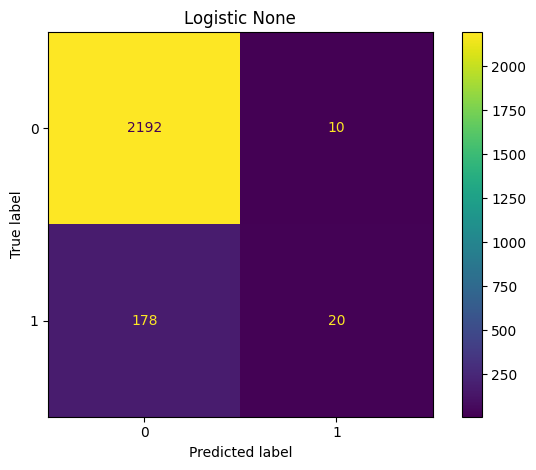

,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
Logistic balanced,0.729583,0.181946,0.651515,0.284454,0.776177,0.312264,925


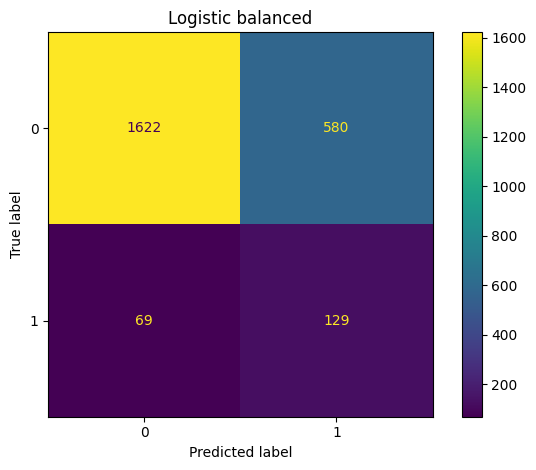

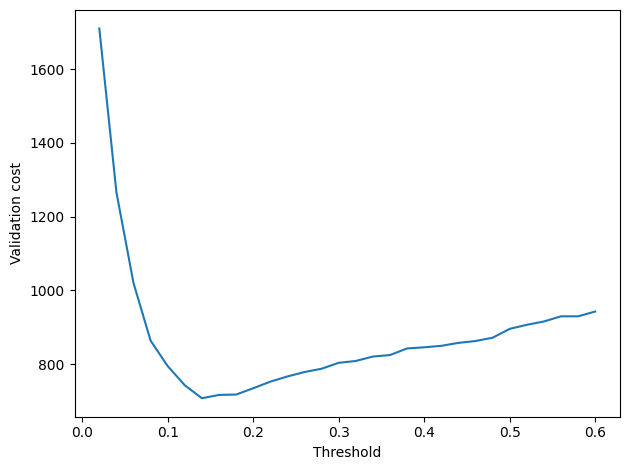

Chosen threshold 0.13999999999999999


,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
Logistic cost threshold,0.844583,0.265416,0.5,0.34676,0.776842,0.314395,769


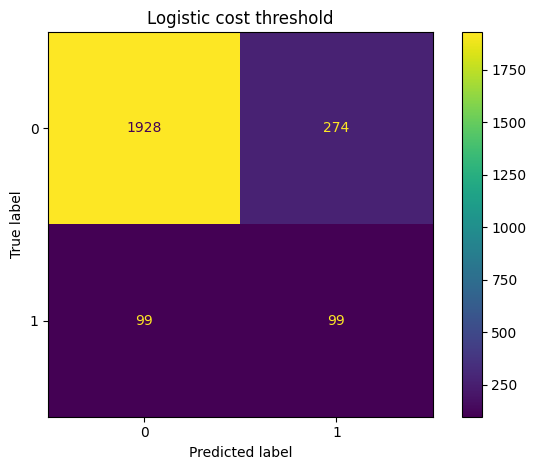

,odds_ratio
num__age,0.930006
num__years_employed,1.128032
num__income,0.782236
num__household,0.908812
num__balance,1.007927
num__products,0.963598
num__loan,0.798061
num__tenure,0.931292
num__interest,0.963987
num__loan_income,1.488696


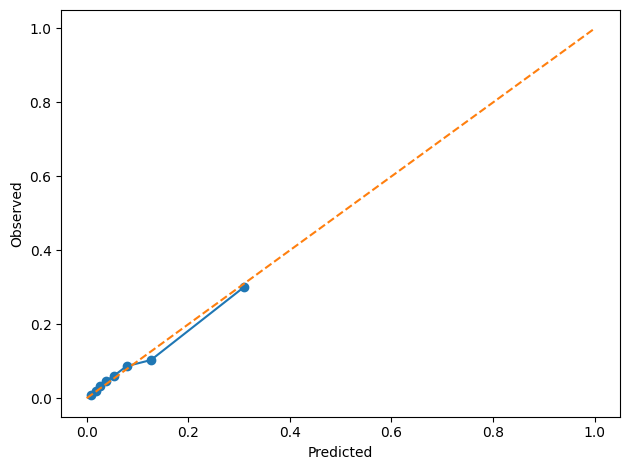

In [ ]:
for weight in [None,'balanced']:
    e=model(LogisticRegression(max_iter=500,class_weight=weight)).fit(X.iloc[A],y.iloc[A]); evaluate('Logistic '+str(weight),e)
log=model(LogisticRegression(max_iter=500)).fit(X.iloc[T],y.iloc[T]); pv=log.predict_proba(X.iloc[V])[:,1]
thresholds=np.arange(.02,.61,.02); costs=[metrics(y.iloc[V],pv>=t,pv)['cost'] for t in thresholds]; th=thresholds[np.argmin(costs)]
plt.plot(thresholds,costs); plt.xlabel('Threshold'); plt.ylabel('Validation cost'); show('threshold_cost'); print('Chosen threshold',th)
log.fit(X.iloc[A],y.iloc[A]); evaluate('Logistic cost threshold',log,th)
display(pd.Series(np.exp(log[-1].coef_[0]),index=log[0].get_feature_names_out(),name='odds_ratio'))
prob=log.predict_proba(X.iloc[B])[:,1]; obs,avg=calibration_curve(y.iloc[B],prob,n_bins=8,strategy='quantile'); plt.plot(avg,obs,'o-'); plt.plot([0,1],[0,1],'--'); plt.xlabel('Predicted'); plt.ylabel('Observed'); show('calibration')

## Task 7 – K-means
Scale income, balance, products and utilisation. Use silhouette and elbow; compare stability with adjusted Rand index. Default is used only to describe clusters, not to train them.

,k,inertia,silhouette
0,2,34863.276018,0.340662
1,3,28172.266829,0.340342
2,4,22656.754457,0.285647
3,5,18255.600710,0.303063
4,6,15714.562770,0.294615
5,7,14072.546324,0.308814


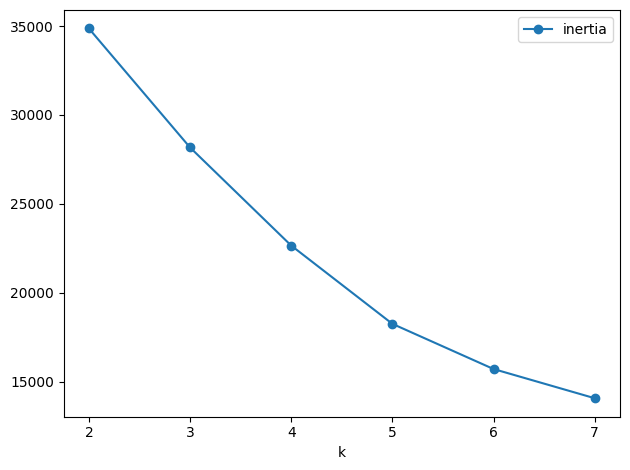

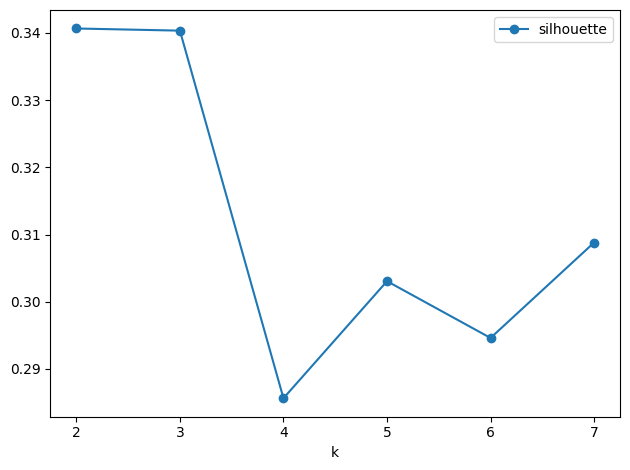

Unscaled silhouette in scaled space: 0.3581884941667131
Stability ARI: 0.9946639764605694
Stability ARI: 0.994664037699437
Stability ARI: 0.9936650400807573


,size,income,balance,products,default_rate
cluster,,,,,
0,7233,338957.5604,36303.8386,1.0,0.0953
1,4767,793198.2774,89015.8152,3.0,0.0634


In [ ]:
features=['income','balance','products','utilisation']; imp=SimpleImputer(strategy='median'); raw=imp.fit_transform(D[features]); Z=StandardScaler().fit_transform(raw)
rows=[]
for kk in range(2,8):
    km=KMeans(kk,n_init=10,random_state=SEED).fit(Z); rows.append([kk,km.inertia_,silhouette_score(Z,km.labels_,sample_size=1500,random_state=SEED)])
cl=pd.DataFrame(rows,columns=['k','inertia','silhouette']); display(cl); cl.plot(x='k',y='inertia',marker='o'); show('elbow'); cl.plot(x='k',y='silhouette',marker='o'); show('silhouette')
kk=int(cl.loc[cl.silhouette.idxmax(),'k']); km=KMeans(kk,n_init=10,random_state=SEED).fit(Z); un=KMeans(kk,n_init=10,random_state=SEED).fit(raw); print('Unscaled silhouette in scaled space:',silhouette_score(Z,un.labels_,sample_size=1500,random_state=SEED))
for seed in [1,2,3]:
    other=KMeans(kk,n_init=10,random_state=seed).fit(Z[rng.choice(N,N//2,False)]); print('Stability ARI:',adjusted_rand_score(km.labels_,other.predict(Z)))
profile=D.assign(cluster=km.labels_).groupby('cluster').agg(size=('default','size'),income=('income','median'),balance=('balance','median'),products=('products','median'),default_rate=('default','mean')); table(profile,'cluster_profiles')

## Task 8 – Model comparison
Compare on identical holdout rows. Accuracy is misleading because most customers do not default.

,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
Baseline,0.9175,0.0000,0.0000,0.0000,0.5000,0.0825,990.0
kNN False,0.9025,0.1087,0.0253,0.0410,0.5273,0.0877,1006.0
kNN True,0.9012,0.2174,0.0758,0.1124,0.6029,0.1200,969.0
CART,0.6862,0.1620,0.6717,0.2610,0.7367,0.2204,1013.0
Logistic None,0.9217,0.6667,0.1010,0.1754,0.7768,0.3144,900.0
Logistic balanced,0.7296,0.1819,0.6515,0.2845,0.7762,0.3123,925.0
Logistic cost threshold,0.8446,0.2654,0.5000,0.3468,0.7768,0.3144,769.0


,batch_ms_per_customer
Baseline,0.005023
kNN False,0.056945
kNN True,0.055030
CART,0.007569
Logistic None,0.015649
Logistic balanced,0.022398
Logistic cost threshold,0.029580


Baseline CV F1 mean/std: 0.0 0.0
kNN True CV F1 mean/std: 0.1291958948821694 0.0038470879876177496
CART CV F1 mean/std: 0.2832035868348309 0.018670857813884556
Logistic balanced CV F1 mean/std: 0.3018371936017181 0.01581733730882724


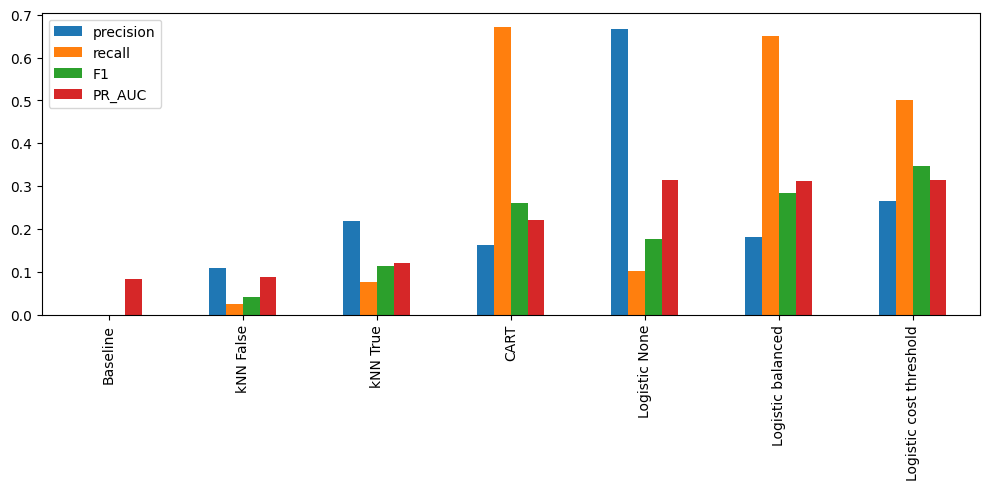

In [ ]:
comparison=pd.DataFrame(results).T; table(comparison,'classifier_comparison'); display(pd.Series(times,name='batch_ms_per_customer'))
for name in ['Baseline','kNN True','CART','Logistic balanced']:
    scores=cross_val_score(models[name][0],X.iloc[A],y.iloc[A],cv=CV,scoring='f1'); print(name,'CV F1 mean/std:',scores.mean(),scores.std())
comparison[['precision','recall','F1','PR_AUC']].plot.bar(figsize=(10,5)); show('model_comparison')

## Task 9 – Compare predictions with observations

In [ ]:
print('kNN scaled vs unscaled F1:',comparison.loc[['kNN True','kNN False'],'F1'].to_dict()); print('Highest recall:',comparison.recall.idxmax()); print('Tree train F1:',tr,'CV F1:',va); print('Selected clusters:',kk)

kNN scaled vs unscaled F1: {'kNN True': 0.11235955056179775, 'kNN False': 0.040983606557377046}
Highest recall: CART
Tree train F1: [0.2418751231041954, 0.27714631197097944, 0.3135593220338983, 0.4409543944427665, 0.7578947368421053] CV F1: [np.float64(0.24109337569870307), np.float64(0.2792824956510262), np.float64(0.25986018359054613), np.float64(0.22894394367793103), np.float64(0.22386667863249002)]
Selected clusters: 2


## Task 10 – Interpret and recommend
Use observed cost, minority recall and explainability jointly. A logistic model offers auditable coefficients, but a coefficient is not by itself a lawful rejection reason. Monitor drift, calibration, error costs and group disparities; obtain independent validation before any deployment.

In [ ]:
print('Lowest measured test cost:',comparison.cost.idxmin()); print('Largest logistic coefficients:'); display(pd.Series(log[-1].coef_[0],index=log[0].get_feature_names_out()).abs().sort_values(ascending=False).head())
audit=D.iloc[B][['gender','default']].copy(); audit['flag']=prob>=th
for group,gp in audit.groupby('gender'):
    print(group,'flag rate',gp.flag.mean(),'recall',recall_score(gp.default,gp.flag,zero_division=0),'false positive rate',gp.loc[gp.default==0,'flag'].mean())

Lowest measured test cost: Logistic cost threshold
Largest logistic coefficients:


,0
num__late,0.827636
num__utilisation,0.635989
num__loan_income,0.397901
num__income,0.245599
num__loan,0.225570


F flag rate 0.1513911620294599 recall 0.5631067961165048 false positive rate 0.11349419124218052
M flag rate 0.15959252971137522 recall 0.43157894736842106 false positive rate 0.13573407202216067


## Task 11 – Digital lending design challenge
120 noisy attributes and 2% default prevalence reduce signal-to-noise and make accuracy even less useful. Compare noisy and reduced features on the same split. Use PR-AUC, F1, recall and timing; use batch scoring and sampled k-means. Recommend modification if measurements support it. The prototype does not prove a production 200 ms SLA.

In [ ]:
rare=rng.binomial(1,expit(brentq(lambda a:expit(a+risk).mean()-.02,-30,10)+risk)); wide=pd.concat([X,pd.DataFrame(rng.normal(size=(N,120)),columns=[f'noise_{i}' for i in range(120)])],axis=1)
a,b=train_test_split(np.arange(N),test_size=.2,stratify=rare,random_state=SEED); a,v=train_test_split(a,test_size=.25,stratify=rare[a],random_state=SEED)
bench=[]
for scenario,xx in [('120 extra predictors',wide),('Reduced predictors',X)]:
    for name,est in [('kNN',KNeighborsClassifier(k)),('CART',DecisionTreeClassifier(max_depth=5,min_samples_leaf=20,class_weight='balanced',random_state=SEED)),('Logistic',LogisticRegression(max_iter=500,class_weight='balanced'))]:
        pipe=make_pipeline(prep(True,list(xx.columns)),est); start=time.perf_counter(); pipe.fit(xx.iloc[a],rare[a]); fit=time.perf_counter()-start
        vp=pipe.predict_proba(xx.iloc[v])[:,1]; ts=np.arange(.01,.96,.03); threshold=min(ts,key=lambda t:metrics(rare[v],vp>=t,vp)['cost'])
        start=time.perf_counter(); pp=pipe.predict_proba(xx.iloc[b])[:,1]; elapsed=time.perf_counter()-start
        met=metrics(rare[b],pp>=threshold,pp); bench.append(dict(scenario=scenario,model=name,fit_s=fit,batch_ms_per_user=elapsed*1000/len(b),projected_weekly_seconds=elapsed/len(b)*3000000,threshold=threshold,**met))
    zz=prep(True,list(xx.columns)).fit_transform(xx); start=time.perf_counter(); cluster=KMeans(kk,n_init=3,random_state=SEED).fit(zz[a]); labels=cluster.predict(zz[b]); print(scenario,'KMeans time',time.perf_counter()-start,'silhouette',silhouette_score(zz[b],labels,sample_size=1000,random_state=SEED),'array MB',zz.nbytes/1e6)
table(pd.DataFrame(bench),'challenge'); print('Rare default fraction',rare.mean())

120 extra predictors KMeans time 0.2825499430000491 silhouette 0.01645487074614528 array MB 13.44
Reduced predictors KMeans time 0.03527993500000548 silhouette 0.1261363676531175 array MB 1.92


,scenario,model,fit_s,batch_ms_per_user,projected_weekly_seconds,threshold,accuracy,precision,recall,F1,ROC_AUC,PR_AUC,cost
0,120 extra predictors,kNN,0.2030,0.0959,287.5686,0.67,0.9825,0.0000,0.0000,0.0000,0.5370,0.0208,210
1,120 extra predictors,CART,1.0289,0.0115,34.5298,0.91,0.9788,0.0000,0.0000,0.0000,0.5829,0.0265,219
2,120 extra predictors,Logistic,0.4150,0.0109,32.6533,0.94,0.9504,0.1111,0.2619,0.1560,0.7628,0.1840,243
3,Reduced predictors,kNN,0.0537,0.0496,148.6616,0.67,0.9825,0.0000,0.0000,0.0000,0.5244,0.0192,210
4,Reduced predictors,CART,0.0833,0.0048,14.3848,0.85,0.9771,0.2759,0.1905,0.2254,0.7279,0.0859,191
5,Reduced predictors,Logistic,0.0518,0.0048,14.3236,0.94,0.9792,0.3462,0.2143,0.2647,0.7569,0.1728,182


Rare default fraction 0.0175


### Final submission
Use actual outputs, explain three tree rules from the printed tree, name clusters using the profiles, and discuss whether the measured results support modification. Timing excludes network and production load. All tables and figures saved under CO5_outputs. References: scikit-learn, SciPy, NumPy, Pandas and Matplotlib documentation; synthetic generator above.